# Revisiones

Cuanto corrige el INDEC sus datos despues de publicarlos?

La API solo tiene el dato vigente, y la ingesta guarda versiones recien desde noviembre de 2026. Para no esperar anios, reconstrui la historia con los informes de prensa: quedan online tal como salieron, con el dato que se publico ese dia.

- `src/monitor/informes.py` baja el listado de informes tecnicos y los pdf del mayorista (desde mar-2018, base dic-2015) y del IPC (desde 2017).
- `src/monitor/extraer_pdf.py` saca de cada pdf el cuadro de variacion mensual por division: 32 aperturas x 3 indices en el mayorista, 13 divisiones x 7 regiones en el IPC.
- En dbt, `fct_primer_dato` cruza cada primer dato con el valor de hoy en la API.

Los informes de feb a jun de 2017 eran solo de GBA y con otras categorias, quedan afuera. Leer los pdf tuvo sus vueltas: en 2017 el cero se escribia con dos rayas, en diciembre vienen dos tablas en la misma pagina y algunos nombres cambian de un anio a otro. Todo eso esta en los tests.

In [1]:
import matplotlib.pyplot as plt

from monitor import analisis as a

a.estilo()
con = a.conectar()
primer = con.execute("select * from fct_primer_dato").df()
calendario = primer[["dataset", "fecha", "publicado"]].drop_duplicates()

## 1. Primer dato contra dato actual

In [2]:
resumen = (
    primer.dropna(subset=["valor_actual"])
    .groupby("dataset")
    .agg(
        informes=("archivo", "nunique"),
        desde=("fecha", "min"),
        hasta=("fecha", "max"),
        datos=("revision", "size"),
        corregidos=("revision", lambda s: (s != 0).sum()),
        mayor_correccion=("revision", lambda s: s.abs().max()),
    )
)
resumen

,informes,desde,hasta,datos,corregidos,mayor_correccion
dataset,,,,,,
ipc,113,2017-06-01,2026-10-01,10283,0,0.0
mayorista,105,2018-02-01,2026-10-01,9975,0,0.0


**Ninguno.** En mas de 20 mil datos, el primer dato publicado es igual al de hoy. El ultimo mes del mayorista sale marcado como provisorio, pero al decimal que se publica nunca cambio.

Para descartar que la API guarde la variacion "como se publico" mientras corrige los indices por debajo, recalcule la variacion desde los indices: coincide en todos los casos salvo seis, que difieren en 0.1 por redondeo.

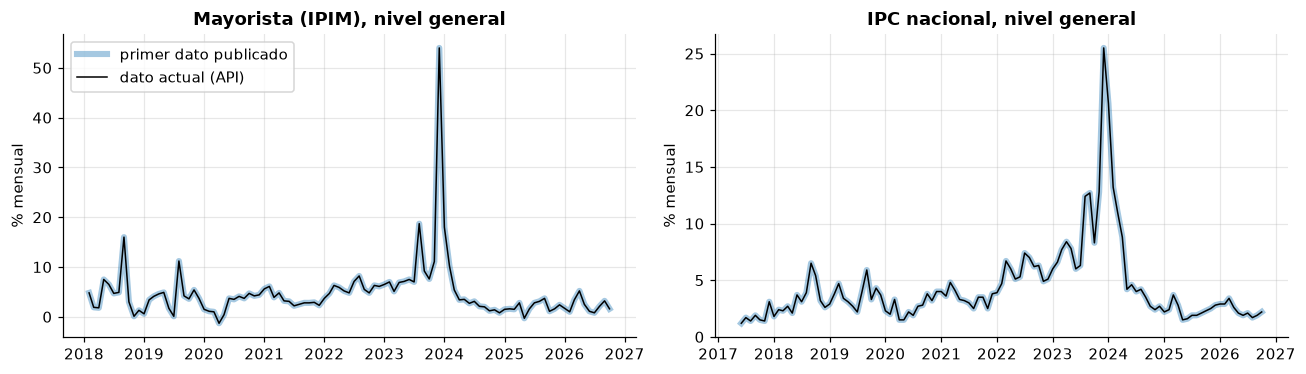

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
series = [
    ("mayorista", "IPIM", "Total del pais", "NG", "Mayorista (IPIM), nivel general"),
    ("ipc", "IPC", "Nacional", "0", "IPC nacional, nivel general"),
]
for ax, (ds, ind, reg, cod, titulo) in zip(axes, series, strict=True):
    s = primer[
        (primer.dataset == ds)
        & (primer.indicador == ind)
        & (primer.region == reg)
        & (primer.codigo == cod)
    ].sort_values("fecha")
    ax.plot(s.fecha, s.valor_publicado, lw=4, alpha=0.4, label="primer dato publicado")
    ax.plot(s.fecha, s.valor_actual, "k", lw=1, label="dato actual (API)")
    ax.set_title(titulo)
    ax.set_ylabel("% mensual")
axes[0].legend()
plt.tight_layout()
plt.show()

Las dos lineas se pisan en todos los meses, incluidos los picos de 2018-2019 y de diciembre de 2023.

Para el pronostico es una buena noticia: el backtest usaba datos "ya revisados" y lo habia marcado como limitacion. Como el primer dato es el definitivo, el backtest no esta inflado por eso.

## 2. Lo que no se pudo medir

In [4]:
rest = primer[
    (primer.dataset == "ipc") & (primer.codigo.isin(["0", "11"])) & (primer.region == "Nacional")
]
rest = rest[(rest.fecha >= "2020-03-01") & (rest.fecha <= "2020-08-01")]
rest.pivot(index="fecha", columns="nombre", values="valor_publicado")

nombre,nivel general,restaurantes y hoteles
fecha,,
2020-03-01,3.3,2.2
2020-04-01,1.5,1.5
2020-05-01,1.5,1.5
2020-06-01,2.2,2.2
2020-07-01,1.9,1.9
2020-08-01,2.7,1.9


Entre abril y julio de 2020 restaurantes tiene exactamente la variacion del nivel general: estaban cerrados, no se pudo relevar y se imputo. Esa imputacion nunca se reemplazo, sigue igual en la API (en el indice figura como `///`). No es una correccion, pero conviene saberlo antes de usar esos meses.

## 3. Cuando publica el INDEC

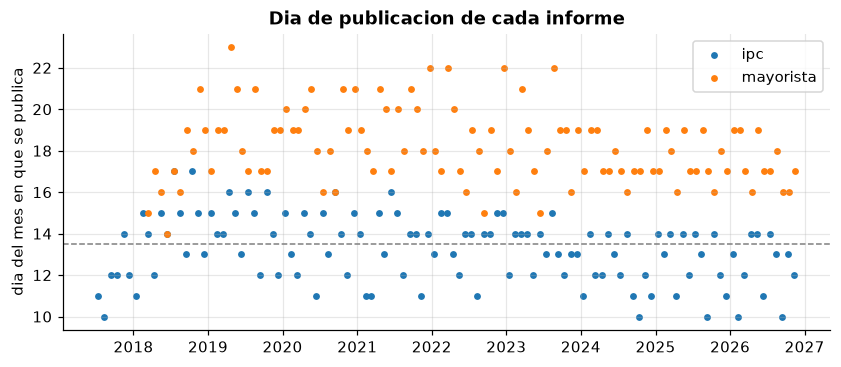

,min,50%,max
dataset,,,
ipc,10.0,13.0,17.0
mayorista,14.0,18.0,23.0


In [5]:
calendario["dia"] = calendario.publicado.dt.day
calendario["anio"] = calendario.publicado.dt.year
fig, ax = plt.subplots(figsize=(9, 3.5))
for ds, color in [("ipc", "C0"), ("mayorista", "C1")]:
    s = calendario[calendario.dataset == ds]
    ax.scatter(s.publicado, s.dia, s=12, color=color, label=ds)
ax.axhline(13.5, color="gray", ls="--", lw=1)
ax.set_ylabel("dia del mes en que se publica")
ax.set_title("Dia de publicacion de cada informe")
ax.legend()
plt.show()
calendario.groupby("dataset").dia.describe()[["min", "50%", "max"]]

El IPC sale entre el 10 y el 17 (mediana 13). El mayorista, entre el 14 y el 23 (mediana 18), y nunca antes que el IPC del mismo mes (en 3 meses salieron el mismo dia).

Esto sirvio para encontrar un error del pronostico. Habia supuesto que el mayorista sale cerca del 19 y usaba el dolar del 1 al 15 del mes que se pronostica. Pero en 4 de los 105 meses salio el 14 o el 15, asi que en esos meses el modelo veia un dia o dos que todavia no se conocian. Ahora `fct_bcra_mensual` corta el dolar el dia anterior a la publicacion real de cada mes (y si la fecha todavia no esta en el calendario, el 13). El error del pronostico quedo igual (2.24 pp), asi que la filtracion no inflaba el resultado, pero ahora no esta.

## 4. De aca en adelante

La ingesta guarda cada version que publica el INDEC, asi que si algun dia corrige un dato se va a ver en `fct_revisiones`. Y el registro de pronosticos guarda lo que dijo el modelo cada mes, para medir el error real contra lo que se publique.

## Resumen

- En 9 anios el INDEC no corrigio ninguna variacion mensual del IPC ni del mayorista, al decimal que publica. El "provisorio" del mayorista nunca cambio.
- El backtest del pronostico no esta sesgado por usar datos revisados.
- Restaurantes de abril a julio de 2020 es una imputacion que quedo para siempre.
- El calendario real de publicacion destapo una filtracion chica en el pronostico, ya corregida.